# Wyniki: cały arkusz

Pilot: cały system na wszystkich budynkach jednego arkusza, na tanim modelu Haiku 5.5, żeby sprawdzić potok. Docelowo system ma działać na otwartym modelu, np. Qwen. W tym przebiegu: rekord BDOT10k, widoki i fasady, rubryka skalibrowana na NSP 2021 bez kwadratów z tego arkusza oraz pętla uzgadniania (`eksperymenty/arkusz_haiku.toml`). Budynki przy krawędzi bez pełnego widoku dostają szacunek z samego rekordu. Liczby dla każdego budynku: `wyniki/eksperymenty/arkusz_haiku.csv`.

Notatnik czyta zapisane wyniki i niczego nie wywołuje. Jednostką oceny liczby mieszkańców są kwadraty NSP 2021, w których szacunek ma każdy budynek mieszkalny. Dla pojedynczego budynku nie mamy referencji: danych o wodzie z MPWiK nie ma i mogą się nie pojawić.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 88}}

import json
import re
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from agenci import BAZA, PRZEBIEGI
from agenci.estymatory import ze_wzoru
from agenci.ewaluacja import ocena_kwadratow, podsumowanie, porownaj_sumy, sumy_kwadratow, wczytaj
from agenci.karta import zbuduj_karte
from agenci.statystyka import budynki_w_kwadratach
from ortofoto.arkusze import czytaj, zasieg
from ortofoto.budynki import wczytaj_budynki

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ececec", "axes.axisbelow": True})
KOLORY = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # kategorie, zawsze w tej kolejności
TUSZ, SZARY = "#333333", "#9a9a9a"
ROZJAZD = LinearSegmentedColormap.from_list("rozjazd", ["#1c5cab", "#86b6ef", "#f0efec", "#f2a27e", "#c2470f"])  # mało / dużo
NIEBIESKI = LinearSegmentedColormap.from_list("niebieski", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def tys(x):
    return f"{x:,.0f}".replace(",", " ")


def po_polsku(tekst):
    """Przecinek dziesiętny w tekście wyświetlanym czytelnikowi."""
    return re.sub(r"(\d)\.(\d)", r"\1,\2", tekst)


bud = wczytaj_budynki()
miasto, kw = budynki_w_kwadratach(zasieg())
wynik = wczytaj("arkusz_haiku").set_index("budynek")
dialog = pd.read_csv(PRZEBIEGI / "arkusz_haiku__dialog.csv").fillna({"zmiana": ""})
bilanse = pd.read_csv(PRZEBIEGI / "arkusz_haiku__bilans.csv").set_index("kod")
with sqlite3.connect(BAZA) as db:
    wydano = db.execute("SELECT SUM(koszt_usd) FROM wywolania").fetchone()[0]
    rubryka_l1 = json.loads(db.execute("SELECT odpowiedz FROM wywolania WHERE rola = 'rubryka' AND model = 'claude-haiku-5-5'").fetchone()[0])

display(Markdown(po_polsku(f"**Wszystkie przebiegi.** Łącznie zapłacono {wydano:.2f} USD. `usd` to koszt świadka, tak jakby przebieg szedł sam, bez pamięci odpowiedzi. "
                           "Próbki 40 budynków nie mają kompletnych kwadratów; porównanie modeli na nich jest w `proof_of_concept.ipynb`. Pętlę oceniamy na kwadratach sprzed uzgadniania.")))
podsumowanie().round(3)

**Wszystkie przebiegi.** Łącznie zapłacono 2,00 USD. `usd` to koszt świadka, tak jakby przebieg szedł sam, bez pamięci odpowiedzi. Próbki 40 budynków nie mają kompletnych kwadratów; porównanie modeli na nich jest w `proof_of_concept.ipynb`. Pętlę oceniamy na kwadratach sprzed uzgadniania.

,budynki,bledy,usd,suma_mieszkancow,kond_mae,kond_trafne,mieszk_trafnosc,mieszk_f1,n_kwadratow,kw_spearman,kw_spearman_lo,kw_spearman_hi,kw_wape,kw_wape_lo,kw_wape_hi
przebieg,,,,,,,,,,,,,,,
arkusz_haiku,341,0,0.286,5617.937,0.298,0.789,0.994,0.996,15,0.889,0.636,0.982,0.164,0.103,0.224
model_haiku_s2_bez_tabeli,40,0,0.031,1413.650,0.811,0.486,0.925,0.954,0,NaN,NaN,NaN,NaN,NaN,NaN
model_opus_s2_bez_tabeli,40,0,0.852,1466.552,1.000,0.432,0.950,0.969,0,NaN,NaN,NaN,NaN,NaN,NaN
model_sonnet_s2_bez_tabeli,40,0,0.387,1635.640,0.811,0.595,0.950,0.969,0,NaN,NaN,NaN,NaN,NaN,NaN
objetosc,341,0,0.000,2596995.130,NaN,NaN,0.724,0.840,15,0.311,-0.331,0.887,0.698,0.131,1.279
objetosc_bdot,341,0,0.000,1431834.230,NaN,NaN,1.000,1.000,15,0.846,0.518,0.977,0.209,0.110,0.316
petla_sonnet_proba,25,0,0.265,370.968,0.917,0.417,1.000,1.000,3,0.500,-1.000,1.000,0.466,0.000,0.879


## Liczba mieszkańców budynku

**Budynki: 341, błędy: 0.** Zamieszkane: 247, łącznie 5 618 os. (mediana 20, maksimum 106 os. na budynek). Bez zdjęć, z samego rekordu: 30 bud., 532 os.

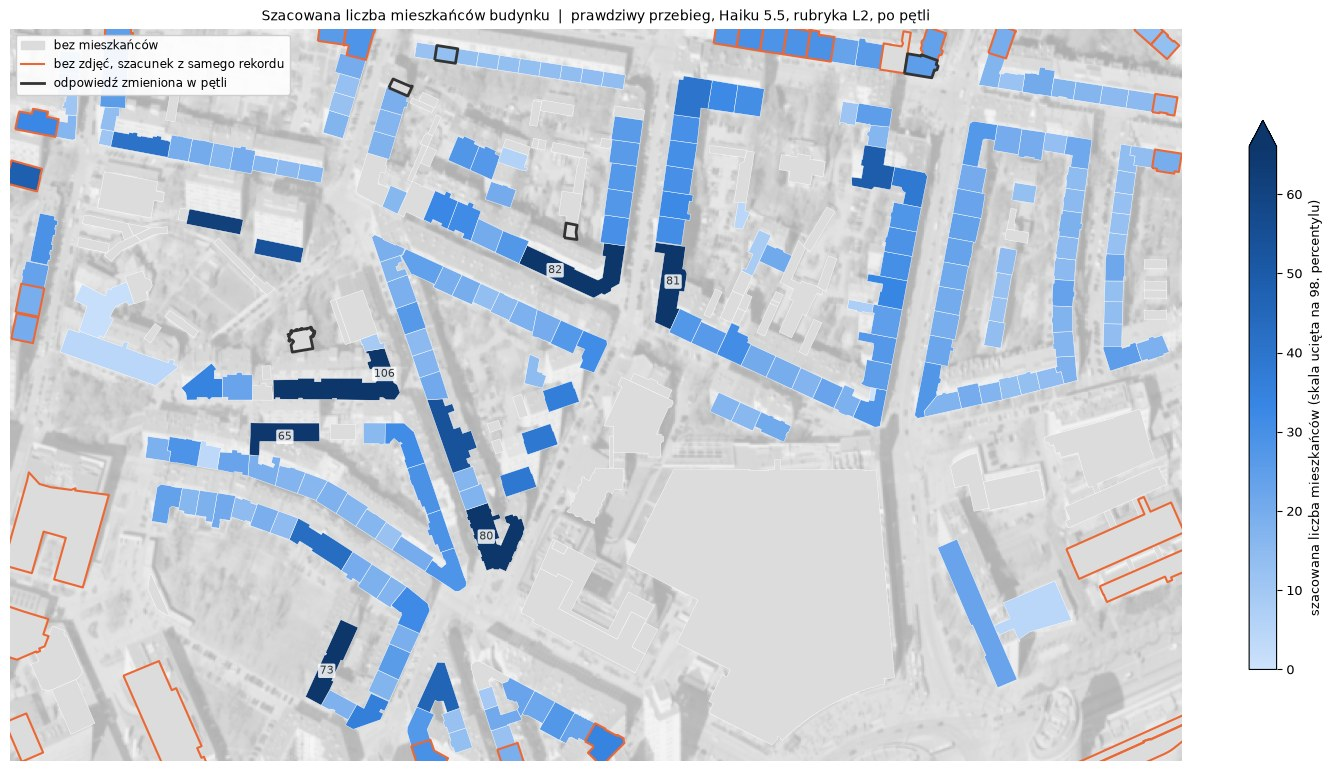

In [2]:
zamieszkane = wynik.mieszkancy[wynik.mieszkancy > 0]
bez_zdjec = wynik[wynik.liczba_widokow == 0]
display(Markdown(f"**Budynki: {len(wynik)}, błędy: {int(wynik.blad.notna().sum())}.** Zamieszkane: {len(zamieszkane)}, łącznie {tys(wynik.mieszkancy.sum())} os. "
                 f"(mediana {zamieszkane.median():.0f}, maksimum {zamieszkane.max():.0f} os. na budynek). Bez zdjęć, z samego rekordu: {len(bez_zdjec)} bud., {tys(bez_zdjec.mieszkancy.sum())} os."))

x0, y0, x1, y1 = zasieg().bounds
img, ext = czytaj("N", zasieg().bounds, 1.0)
tlo = 255 - (255 - img.mean(2)) * 0.35
mapa = bud.join(wynik[["mieszkancy", "liczba_widokow", "zmieniony"]])
fig, ax = plt.subplots(figsize=(15, 7.6), layout="constrained")
ax.imshow(tlo, extent=ext, cmap="gray", vmin=0, vmax=255)
mapa[mapa.mieszkancy.fillna(0) == 0].plot(ax=ax, color="#dcdcdc", edgecolor="white", linewidth=0.3)
mapa[mapa.mieszkancy > 0].plot(ax=ax, column="mieszkancy", cmap=NIEBIESKI, vmin=0, vmax=mapa.mieszkancy[mapa.mieszkancy > 0].quantile(0.98), edgecolor="white", linewidth=0.3,
                               legend=True, legend_kwds={"label": "szacowana liczba mieszkańców (skala ucięta na 98. percentylu)", "shrink": 0.75})
mapa[mapa.liczba_widokow == 0].boundary.plot(ax=ax, color=KOLORY[1], linewidth=1.5)
mapa[mapa.zmieniony == True].boundary.plot(ax=ax, color=TUSZ, linewidth=2)  # noqa: E712
for _, b in mapa.nlargest(6, "mieszkancy").iterrows():
    p = b.geometry.representative_point()
    ax.text(p.x, p.y, f"{b.mieszkancy:.0f}", ha="center", va="center", fontsize=8, color=TUSZ, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.legend(handles=[Patch(color="#dcdcdc", label="bez mieszkańców"), Line2D([], [], color=KOLORY[1], lw=1.5, label="bez zdjęć, szacunek z samego rekordu"),
                   Line2D([], [], color=TUSZ, lw=2, label="odpowiedź zmieniona w pętli")], loc="upper left", fontsize=8.5, framealpha=0.92)
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Szacowana liczba mieszkańców budynku  |  prawdziwy przebieg, Haiku 5.5, rubryka L2, po pętli")
ax.set_axis_off()
plt.show()

## Czy sumy zgadzają się ze spisem?

To jedyna ocena liczby mieszkańców, jaką dziś mamy. Stan przed pętlą jest oceną niezależną, bo rubrykę dopasowano bez tych kwadratów. Po pętli jest kolista, bo agent widział te sumy.

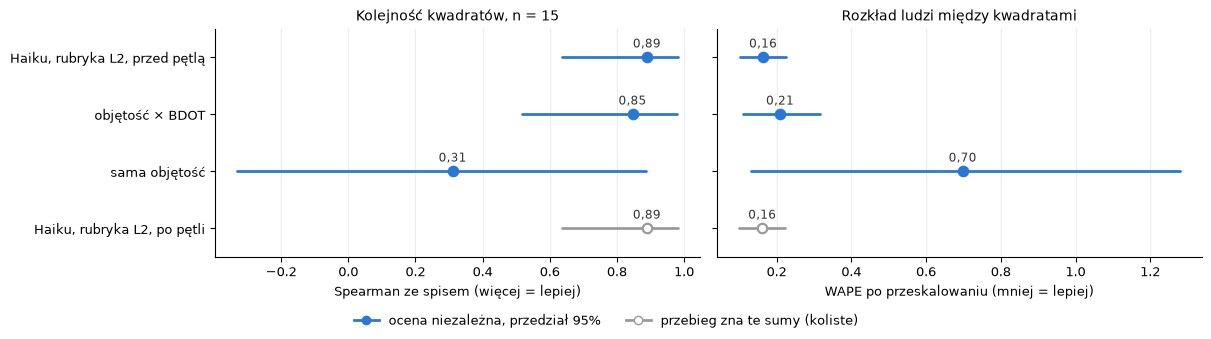

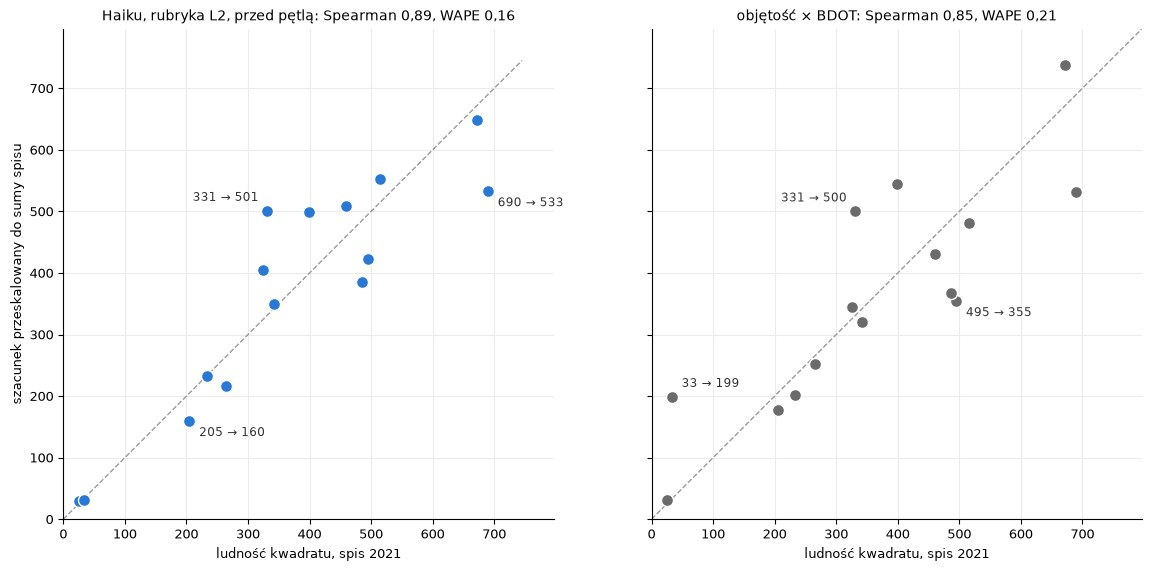

**Haiku a objętość × BDOT:** różnica Spearmana +0,04 [-0,09; +0,23], różnica WAPE -0,05 [-0,15; +0,04]. Oba przedziały obejmują zero, więc przewaga nie jest rozstrzygnięta.

**Jeden kwadrat ma tu dużą wagę.** W kwadracie z akademikiem spis podaje 33 os., baseline daje 199, a Haiku 32, bo świadek czyta w rekordzie `dom studencki`, a rubryka daje tej klasie niską gęstość. To zasługa rekordu i rubryki, a nie obrazu. Bez tego kwadratu różnica Spearmana to +0,05 [-0,12; +0,29], a WAPE -0,01 [-0,06; +0,05].

**Poziom jest niepewny:** na tych 15 kwadratach spis ma 5 476 os., a szacunek 3 974 os., czyli -27%. Wykresy powyżej usuwają tę różnicę skalą, a liczby w pliku CSV nie są skalowane. Na całym arkuszu to 5 618 os. z rubryką L2, ok. 7 742 os. po przeskalowaniu do spisu z tych kwadratów i 8 791 os. z rubryką z wiedzy Haiku.

In [3]:
PRED = wynik.reset_index()
BDOT, OBJETOSC = wczytaj("objetosc_bdot"), wczytaj("objetosc")
t = pd.DataFrame([ocena_kwadratow(PRED, miasto, kw, "mieszkancy_r0") | {"podpis": "Haiku, rubryka L2, przed pętlą", "kolista": False},
                  ocena_kwadratow(BDOT, miasto, kw) | {"podpis": "objętość × BDOT", "kolista": False},
                  ocena_kwadratow(OBJETOSC, miasto, kw) | {"podpis": "sama objętość", "kolista": False},
                  ocena_kwadratow(PRED, miasto, kw) | {"podpis": "Haiku, rubryka L2, po pętli", "kolista": True}])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.3), sharey=True, layout="constrained")
for ax, miara, xlabel in ((a, "kw_spearman", "Spearman ze spisem (więcej = lepiej)"), (b, "kw_wape", "WAPE po przeskalowaniu (mniej = lepiej)")):
    for y, w in t.iterrows():
        kolor = SZARY if w.kolista else KOLORY[0]
        ax.plot([w[miara + "_lo"], w[miara + "_hi"]], [y, y], color=kolor, lw=2, solid_capstyle="round", zorder=2)
        ax.scatter(w[miara], y, s=46, facecolor="white" if w.kolista else kolor, edgecolor=kolor, linewidth=1.6, zorder=3)
        ax.annotate(f"{w[miara]:.2f}".replace(".", ","), (w[miara], y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=TUSZ)
    ax.set_yticks(range(len(t)), t.podpis)
    ax.set_ylim(len(t) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
a.set_title(f"Kolejność kwadratów, n = {int(t.n_kwadratow.max())}")
b.set_title("Rozkład ludzi między kwadratami")
fig.legend(handles=[Line2D([], [], marker="o", color=KOLORY[0], lw=2, label="ocena niezależna, przedział 95%"),
                    Line2D([], [], marker="o", color=SZARY, markerfacecolor="white", lw=2, label="przebieg zna te sumy (koliste)")],
           loc="outside lower center", ncols=2, frameon=False)
plt.show()

fig, osie = plt.subplots(1, 2, figsize=(12, 5.6), sharex=True, sharey=True, layout="constrained")
for ax, (podpis, pred, kolumna, kolor) in zip(osie, [("Haiku, rubryka L2, przed pętlą", PRED, "mieszkancy_r0", KOLORY[0]), ("objętość × BDOT", BDOT, "mieszkancy", "#6b6b6b")]):
    suma, ref = sumy_kwadratow(pred, miasto, kw, kolumna)
    s = suma * ref.sum() / suma.sum()
    granica = 1.08 * max(s.max(), ref.max())
    ax.plot([0, granica], [0, granica], color=SZARY, ls="--", lw=1, zorder=1)
    ax.scatter(ref, s, s=75, color=kolor, edgecolor="white", linewidth=1, zorder=3)
    for kod_kwadratu in np.log((s + 1) / (ref + 1)).abs().nlargest(3).index:
        x, y = ref[kod_kwadratu], s[kod_kwadratu]
        w_lewo = y > x and x > 0.2 * granica  # etykieta przy osi szłaby poza wykres
        ax.annotate(f"{x:.0f} → {y:.0f}", (x, y), xytext=(-6, 7) if w_lewo else (7, 7 if y > x else -11), ha="right" if w_lewo else "left", textcoords="offset points", fontsize=8.5, color=TUSZ)
    w = t[t.podpis == podpis].iloc[0]
    ax.set(title=po_polsku(f"{podpis}: Spearman {w.kw_spearman:.2f}, WAPE {w.kw_wape:.2f}"), xlabel="ludność kwadratu, spis 2021", xlim=(0, granica), ylim=(0, granica), aspect="equal")
osie[0].set_ylabel("szacunek przeskalowany do sumy spisu")
plt.show()

a_, ref = sumy_kwadratow(PRED, miasto, kw, "mieszkancy_r0")
b_, _ = sumy_kwadratow(BDOT, miasto, kw)
d = porownaj_sumy(a_, b_, ref)
karty = {i: zbuduj_karte(bud.loc[i], obrazy=False) for i in wynik.index}
suma_l1 = sum(ze_wzoru(o.to_dict(), karty[i], rubryka_l1, True) for i, o in wynik.iterrows())
skalowany_a, skalowany_b = a_ * ref.sum() / a_.sum(), b_ * ref.sum() / b_.sum()
najgorszy = np.log((skalowany_b + 1) / (ref + 1)).abs().idxmax()  # kwadrat, w którym baseline myli się najbardziej
bez = porownaj_sumy(a_.drop(najgorszy), b_.drop(najgorszy), ref.drop(najgorszy))
display(Markdown(po_polsku(f"**Haiku a objętość × BDOT:** różnica Spearmana {d['d_spearman']:+.2f} [{d['d_spearman_lo']:+.2f}; {d['d_spearman_hi']:+.2f}], "
                           f"różnica WAPE {d['d_wape']:+.2f} [{d['d_wape_lo']:+.2f}; {d['d_wape_hi']:+.2f}]. Oba przedziały obejmują zero, więc przewaga nie jest rozstrzygnięta.\n\n"
                           f"**Jeden kwadrat ma tu dużą wagę.** W kwadracie z akademikiem spis podaje {ref[najgorszy]:.0f} os., baseline daje {skalowany_b[najgorszy]:.0f}, a Haiku {skalowany_a[najgorszy]:.0f}, "
                           f"bo świadek czyta w rekordzie `dom studencki`, a rubryka daje tej klasie niską gęstość. To zasługa rekordu i rubryki, a nie obrazu. Bez tego kwadratu różnica Spearmana to {bez['d_spearman']:+.2f} "
                           f"[{bez['d_spearman_lo']:+.2f}; {bez['d_spearman_hi']:+.2f}], a WAPE {bez['d_wape']:+.2f} [{bez['d_wape_lo']:+.2f}; {bez['d_wape_hi']:+.2f}].\n\n"
                           f"**Poziom jest niepewny:** na tych {d['n']} kwadratach spis ma {tys(ref.sum())} os., a szacunek {tys(a_.sum())} os., czyli {a_.sum() / ref.sum() - 1:+.0%}. "
                           f"Wykresy powyżej usuwają tę różnicę skalą, a liczby w pliku CSV nie są skalowane. Na całym arkuszu to {tys(wynik.mieszkancy.sum())} os. z rubryką L2, "
                           f"ok. {tys(wynik.mieszkancy.sum() * ref.sum() / a_.sum())} os. po przeskalowaniu do spisu z tych kwadratów i {tys(suma_l1)} os. z rubryką z wiedzy Haiku.")))

Gdzie szacunek rozjeżdża się ze spisem na mapie. Niebieski znaczy za mało, pomarańczowy za dużo, a etykiety to ludność ze spisu. Gruba ramka wokół kwadratu to flaga rozjazdu.

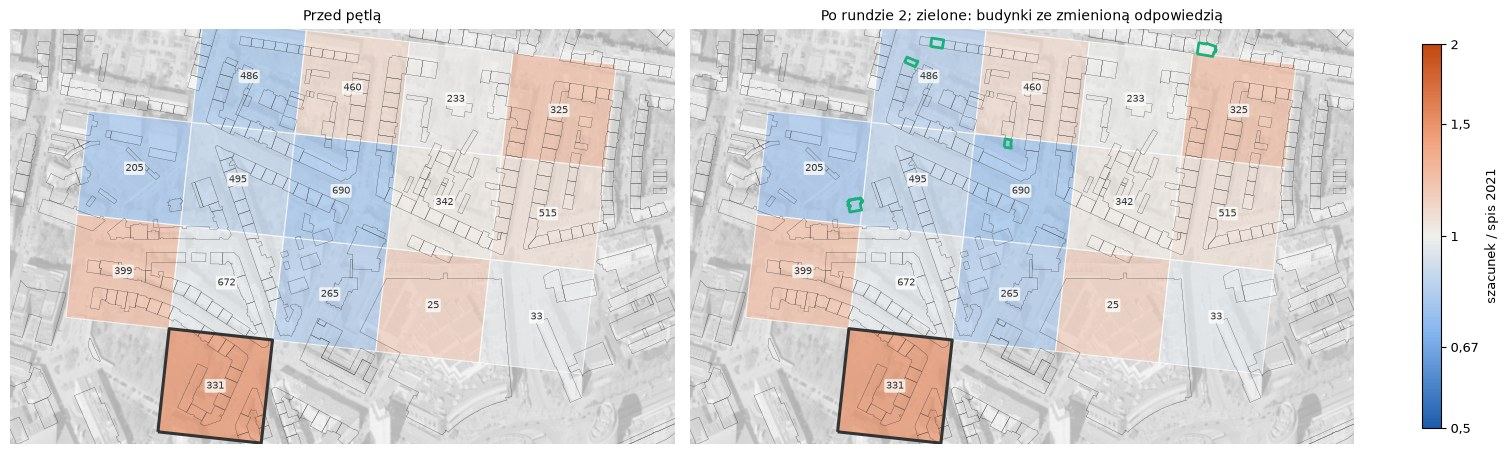

In [4]:
norma = LogNorm(0.5, 2)
zmienione = wynik.index[wynik.zmieniony]
fig, osie = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")
for ax, runda in zip(osie, (0, int(bilanse.runda.max()))):
    r = bilanse[bilanse.runda == runda]
    ax.imshow(tlo, extent=ext, cmap="gray", vmin=0, vmax=255)
    kwadraty = kw.loc[r.index].assign(iloraz=r.iloraz)
    kwadraty.plot(ax=ax, column="iloraz", cmap=ROZJAZD, norm=norma, alpha=0.72, edgecolor="white", linewidth=0.8)
    if r.flaga.any():
        kwadraty[r.flaga].boundary.plot(ax=ax, color=TUSZ, linewidth=2.2)
    bud.boundary.plot(ax=ax, color=TUSZ, linewidth=0.2)
    if runda and len(zmienione):
        bud.loc[zmienione].boundary.plot(ax=ax, color=KOLORY[2], linewidth=2)
    for kod_kwadratu, w in r.iterrows():
        p = kw.geometry[kod_kwadratu].centroid
        if zasieg().contains(p):
            ax.text(p.x, p.y, f"{w.ludnosc:.0f}", ha="center", va="center", fontsize=7.5, color=TUSZ, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
    ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Przed pętlą" if runda == 0 else f"Po rundzie {runda}; zielone: budynki ze zmienioną odpowiedzią")
    ax.set_axis_off()
pasek = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=ROZJAZD), ax=osie, shrink=0.75, label="szacunek / spis 2021")
pasek.set_ticks([0.5, 0.67, 1, 1.5, 2], labels=["0,5", "0,67", "1", "1,5", "2"])
pasek.ax.minorticks_off()
plt.show()

## Kto gdzie mieszka

Typ budynku według świadka i rozkład szacunków. Kamienice dominują, bo tak wygląda ten fragment miasta; ten arkusz nie mówi nic o osiedlach domów jednorodzinnych.

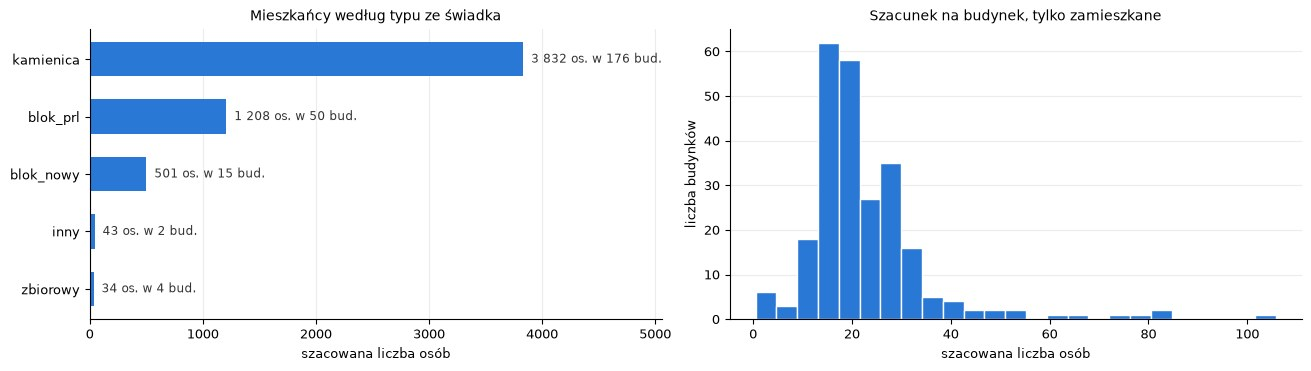

,funkcja,kond_bdot,pow_m2,typ,udzial_mieszkalny,pewnosc,mieszkancy
0,budynek wielorodzinny,6.0,1420.0,kamienica,0.90,0.60,105.74
1,budynek wielorodzinny,6.0,1161.0,blok_nowy,0.85,0.50,81.66
2,budynek wielorodzinny,8.0,863.0,blok_prl,0.85,0.60,80.88
3,budynek wielorodzinny,7.0,1032.0,kamienica,0.80,0.60,79.68
4,budynek wielorodzinny,8.0,738.0,blok_nowy,0.90,0.85,73.28
5,budynek wielorodzinny,8.0,659.0,blok_nowy,0.90,0.80,65.42
6,budynek wielorodzinny,12.0,392.0,blok_prl,0.95,0.85,61.67
7,budynek wielorodzinny,12.0,343.0,blok_prl,0.95,0.85,53.88
8,budynek wielorodzinny,6.0,765.0,kamienica,0.85,0.60,53.78
9,budynek wielorodzinny,5.0,566.0,kamienica,0.85,0.60,49.24


In [5]:
typy = wynik[wynik.mieszkancy > 0].groupby("typ").mieszkancy.agg(["sum", "size"]).sort_values("sum")
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.6), layout="constrained")
a.barh(typy.index, typy["sum"], color=KOLORY[0], height=0.6)
for y, (suma_typu, liczba) in enumerate(zip(typy["sum"], typy["size"])):
    a.text(suma_typu, y, f"  {tys(suma_typu)} os. w {liczba} bud.", va="center", fontsize=8.5, color=TUSZ)
a.set(title="Mieszkańcy według typu ze świadka", xlabel="szacowana liczba osób", xlim=(0, typy["sum"].max() * 1.32))
a.grid(axis="y", visible=False)
b.hist(wynik.mieszkancy[wynik.mieszkancy > 0], bins=25, color=KOLORY[0], edgecolor="white")
b.set(title="Szacunek na budynek, tylko zamieszkane", xlabel="szacowana liczba osób", ylabel="liczba budynków")
b.grid(axis="x", visible=False)
plt.show()

t = wynik.nlargest(10, "mieszkancy").join(bud[["funkcja"]]).join(bud.kondygnacje.rename("kond_bdot"))
t["pow_m2"] = bud.geometry.area.reindex(t.index).round()
t[["funkcja", "kond_bdot", "pow_m2", "typ", "udzial_mieszkalny", "pewnosc", "mieszkancy"]].round(2).reset_index(drop=True)

## Co zrobiła pętla

Wszystkie pytania agenta bilansującego i odpowiedzi świadka w tym przebiegu. Świadek widzi tu rekord BDOT10k, więc poprawki zgodne z rekordem nie są niezależnym potwierdzeniem.

In [6]:
kroki = ["**Flagi rozjazdu po rundach:** " + ", ".join(f"runda {int(n)}: {int(f)}" for n, f in bilanse.groupby("runda").flaga.sum().items()) +
         f". **Suma na arkuszu:** {tys(wynik.mieszkancy_r0.sum())} przed pętlą, {tys(wynik.mieszkancy.sum())} po niej."]
for w in dialog.itertuples():
    if w.rodzaj == "kwadrat":
        k = bilanse[bilanse.runda == w.runda - 1].loc[w.kod]
        kroki.append(f"**Agent, runda {w.runda:.0f}: kwadrat ze spisem {k.ludnosc:.0f} os. i szacunkiem {k.szacunek:.0f} os.** Diagnoza `{w.diagnoza}`.\n\n> {w.uzasadnienie}")
    elif w.rodzaj == "pytanie":
        b = bud.loc[w.budynek]
        kroki.append(f"**{b.funkcja}, {b.geometry.area:.0f} m².** Pytanie: *{w.pytanie}*\n\n> {w.odpowiedz}\n\n"
                     f"Zmiana: {w.zmiana or 'brak'}. Szacunek budynku: {w.mieszkancy_przed:.0f} -> {w.mieszkancy_po:.0f} os.")
display(Markdown("\n\n".join(kroki)))

**Flagi rozjazdu po rundach:** runda 0: 1, runda 1: 1, runda 2: 1. **Suma na arkuszu:** 5 584 przed pętlą, 5 618 po niej.

**Agent, runda 1: kwadrat ze spisem 331 os. i szacunkiem 501 os.** Diagnoza `nieznana`.

> Nadwyżka 170 osób rozkłada się na wiele kamienic z udziałem mieszkalnym 0,8-0,85 oraz na jeden duży blok (654aafca, 101 os.), a opisy świadka nie pozwalają jednoznacznie wskazać, który element za nią odpowiada.

**budynek wielorodzinny, 274 m².** Pytanie: *Czy na widokach E i S widać, że budynek jest ukończony i użytkowany, czy trwają na nim prace budowlane lub rozbiórka? Proszę opisać, co widać na rusztowaniach i na ogrodzonym placu.*

> Na widoku S fasada zwrócona na północ ma regularne rzędy okien i balkonów, a dach jest wykończony, co wskazuje na ukończony budynek. Rusztowania i prace przy ulicy na widoku E dotyczą raczej parteru lub otoczenia, więc zmieniam stan z w_budowie na uzytkowany, ale z mniejszą pewnością.

Zmiana: stan: w_budowie -> uzytkowany. Szacunek budynku: 0 -> 25 os.

**obiekt handlowo-usługowy, 78 m².** Pytanie: *Czy parter od strony N ma witrynę lub wejście do lokalu usługowego, czy tylko okna i wejście mieszkalne? Proszę opisać elementy parteru, na których opiera się ocena typu.*

> Parter od strony N ma dwa okna z roletami i nie widać na nim witryny ani osobnego wejścia usługowego, więc sam parter nie rozstrzyga typu. Na dachu widać jednak urządzenia techniczne (jednostki klimatyzacyjne lub wentylacyjne) w widokach E, S i W, a takie wyposażenie na płaskim dachu jest typowe dla lokalu usługowego, nie domu jednorodzinnego, dlatego zmieniam typ na uslugi.

Zmiana: typ: dom_jednorodzinny -> uslugi; udzial_mieszkalny: 0.9 -> 0.2. Szacunek budynku: 3 -> 0 os.

**obiekt handlowo-usługowy, 200 m².** Pytanie: *Czy parter tego budynku jest zajęty przez lokale usługowe lub handlowe? Proszę opisać, co widać na parterze z widoku E lub W, bo wcześniej nie był dobrze widoczny.*

> Na widokach E i W parter jest słabo widoczny, bo zasłaniają go dachy i rusztowanie, więc nie potwierdzam ani nie wykluczam lokali usługowych. Na elewacji z widoku N okna parteru mają podobny rozmiar i rytm co wyższe kondygnacje, a nie widać witryn ani szyldów, dlatego zostawiam udział mieszkalny bez zmian, choć dane BDOT10k wskazują na przeważającą funkcję usługową.

Zmiana: brak. Szacunek budynku: 6 -> 6 os.

**budynek wielorodzinny, 145 m².** Pytanie: *Czy na widokach E i W widać jedną bryłę z płaskim dachem, czy kilka połączonych brył o różnej wysokości? Proszę opisać, czy balkony z widoku S należą do tego samego obrysu.*

> Poprzednia odpowiedź (usługi, 2 kondygnacje) była błędna: widok S pokazuje w żółtym obrysie fasadę wielorodzinną z balkonami i rzędami okien na około pięciu kondygnacjach, zgodnie z BDOT10k. Na widokach E i W widać płaski dach długiej, niskiej bryły z dwoma sekcjami rozdzielonymi szwem, a balkony z widoku S należą do żółtego obrysu, nie czerwonego, więc część czerwona to niższe, płaskie skrzydło.

Zmiana: typ: uslugi -> blok_prl; kondygnacje: 2 -> 5; udzial_mieszkalny: 0.0 -> 0.9. Szacunek budynku: 0 -> 13 os.

**garaż, 95 m².** Pytanie: *Czy na ścianach widocznych z E i W są drzwi bramowe lub inne oznaki garażu, czy wyłącznie okna mieszkalne na kilku poziomach? Proszę opisać przyziemie i to, czy jest tam brama.*

> Na ścianach widocznych z E i W nie widać okien mieszkalnych na kilku poziomach, tylko jednolite, niskie płaszczyzny; przyziemie nie wygląda na mieszkalne, a niska, płaska bryła z ciemnym dachem i sąsiedztwem parkingu wskazuje na garaż. Wyraźnej bramy nie udaje mi się jednoznacznie wskazać w tak małych wycinkach, ale podziały na ścianie północnej/południowej sugerują segmentowe wjazdy, dlatego poprzednie 4 kondygnacje bloku PRL uznaję za błędne.

Zmiana: typ: blok_prl -> garaz; kondygnacje: 4 -> 1; udzial_mieszkalny: 0.8 -> 0.0. Szacunek budynku: 2 -> 0 os.

**kościół, 211 m².** Pytanie: *Czy na elewacjach widać cechy kościoła, takie jak okna witrażowe, wieża lub portal, czy raczej zwykłe okna mieszkalne? Proszę opisać elewacje, z których widać najwięcej.*

> Na fasadach N, E, S i W widać głównie prostokątne okna bez witraży, portalu ani wyraźnej wieży, więc obraz nie potwierdza kościoła, a fasady są rozmazane. Baza BDOT10k wskazuje kościół, a ten typ według klasyfikacji należy do usług publicznych (uslugi), nie do zamieszkania zbiorowego, dlatego zmieniam typ na uslugi i udział mieszkalny na 0.

Zmiana: typ: zbiorowy -> uslugi; udzial_mieszkalny: 0.5 -> 0.0. Szacunek budynku: 0 -> 0 os.

**Agent, runda 2: kwadrat ze spisem 331 os. i szacunkiem 500 os.** Diagnoza `nowa_zabudowa`.

> Nadwyżka (500 wobec 331 os., iloraz 1.51) koncentruje się w budynku 654aafca (101 os.) i w 7e5b3321, które świadek opisuje jako nowe bloki, a ich identyfikatory mają format nowszych rekordów BDOT10k; data oddania nie jest jednak potwierdzona, więc diagnoza pozostaje niepewna.

**budynek wielorodzinny, 738 m².** Pytanie: *Czy budynek jest ukończony i zamieszkany na wszystkich widocznych kondygnacjach, czy widać na nim oznaki, że wykończenie lub zasiedlenie trwa albo dopiero się zaczęło? Proszę opisać elewacje z widoków W i S oraz to, czy na balkonach i oknach widać mieszkańców lub meble.*

> Na elewacjach W i S okna są osadzone i przeszklone, balkony mają wykończone balustrady, a nie widać rusztowań ani niedokończonych kondygnacji, więc budynek wygląda na ukończony. Na balkonach i w oknach widać zasłony, rośliny i pojedyncze przedmioty, co wskazuje na zamieszkanie, choć przy tej rozdzielczości nie da się wyraźnie zidentyfikować mebli ani ludzi.

Zmiana: brak. Szacunek budynku: 73 -> 73 os.

## Jak to czytać

- **Dla pojedynczego budynku nie ma sprawdzenia.** Ocena dotyczy sum w kwadratach. Danych o wodzie nie mamy, więc liczba na konkretnym budynku to szacunek ze wzoru, a nie pomiar.
- **Przewaga nad baseline'em nie jest rozstrzygnięta.** Przy 15 kwadratach przedziały różnicy obejmują zero, a zysk w WAPE pochodzi prawie w całości z jednego kwadratu z akademikiem. Ten przebieg nie pokazuje też, czy pomagają obrazy, bo porównuje cały system z objętością: do tego potrzebne są warianty bez obrazów i z obrazami innego budynku.
- **Zgodność z BDOT10k jest tu kolista.** Świadek widzi rekord, a jego odpowiedzi czasem wprost się na niego powołują.
- **Zamieszkanie zbiorowe jest prawie na pewno zaniżone.** Rubryka L2 dziedziczy definicję ze spisu, więc akademiki i klasztory dostają od 1 do 23 osób.
- **Pętla mało zmienia.** Ma niewiele flag, a odpowiedź świadka zależy też od sformułowania pytania.